In [ ]:
%load_ext autoreload
%autoreload 2
import sys
import os
sys.path.append(os.path.abspath('../'))

import albumentations as A
from albumentations.pytorch import ToTensorV2
from dataclasses import asdict

from datasets import ReBEN7kDataset, BurnScarsDataset, Sen1Floods11Dataset, C2SegDataset
from utils.config import ReBEN7kDataset_Cfg, BurnScarsDataset_Cfg, Sen1Floods11Dataset_Cfg, C2SegDataset_Cfg
from utils.visualization import plot_images, quant_norm

# %%
# Local Paths from configs/paths/local.yaml
LOCAL_PATHS = {
    "reben_dir": "/mnt/ssd/datasets/reben/BigEarthNet-S2-1%_lmdb/",
    "reben_keys": "/mnt/ssd/datasets/reben/keys-1%.pkl",
    "burn_scars_dir": "/mnt/ssd/datasets/burn_scars/",
    "sen1floods11_dir": "/mnt/ssd/datasets/sen1floods11/",
    "c2seg_dir": "/mnt/ssd/datasets/c2seg/",
}

seed = 42
split = "train"

train_transform_list = [
    A.HorizontalFlip(p=0.5), 
    A.VerticalFlip(p=0.5), 
    A.RandomRotate90(p=1.0)]


# Reben 7k

[LOG] Cached 10876 keys from /mnt/ssd/datasets/reben/keys-1%.pkl
finished dataset init
Number of tiles: 41
Dataset length (Number of crops): None
Margin Y: None, Margin X: None
Epoch 0: first tile offset: None


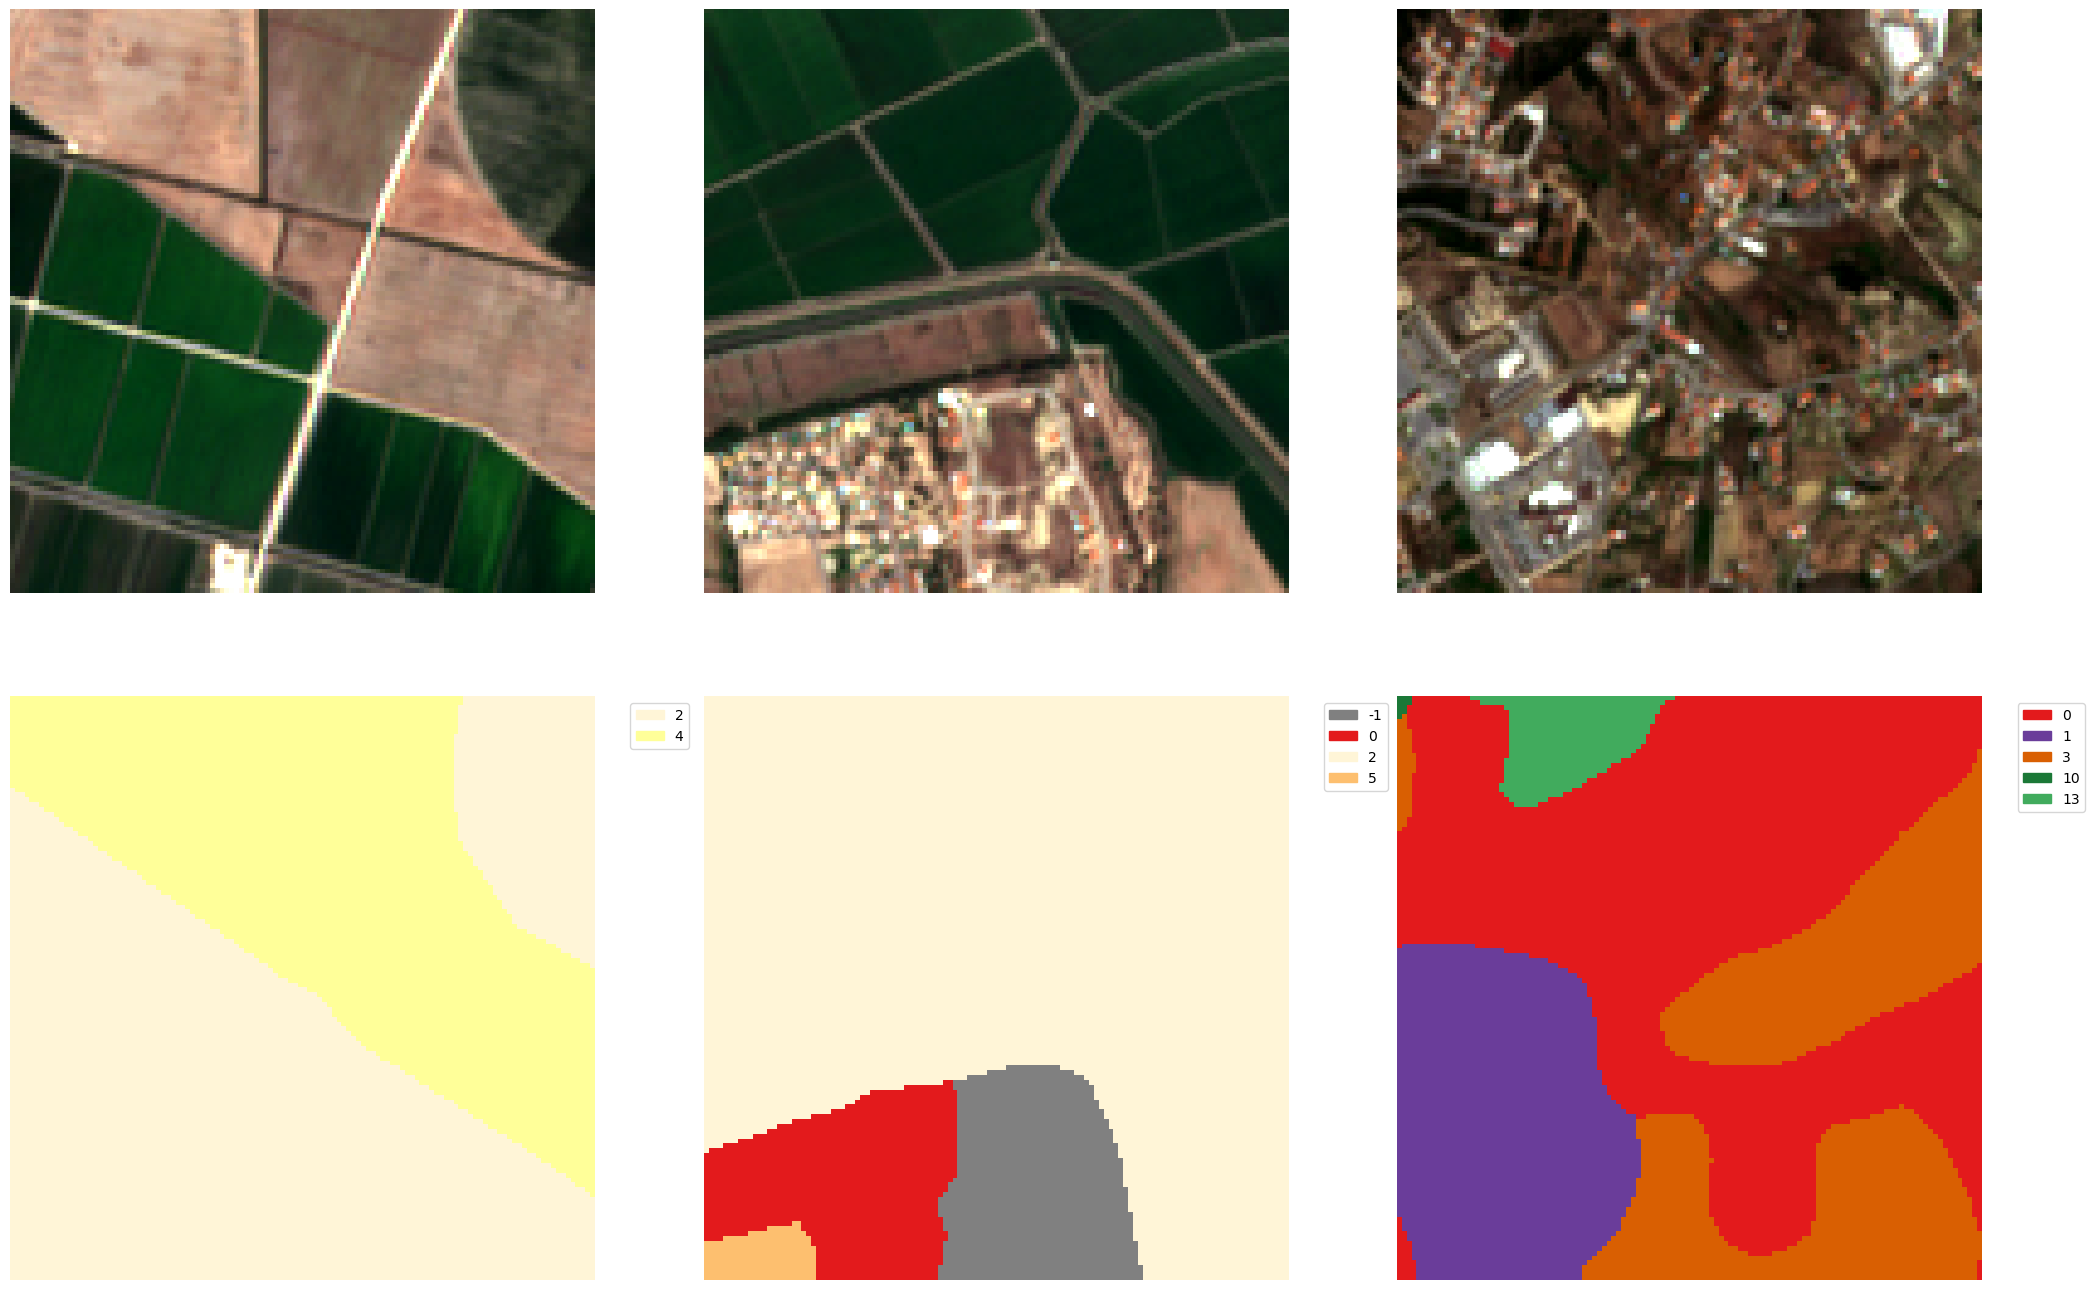

Epoch 1: first tiles offsets: None


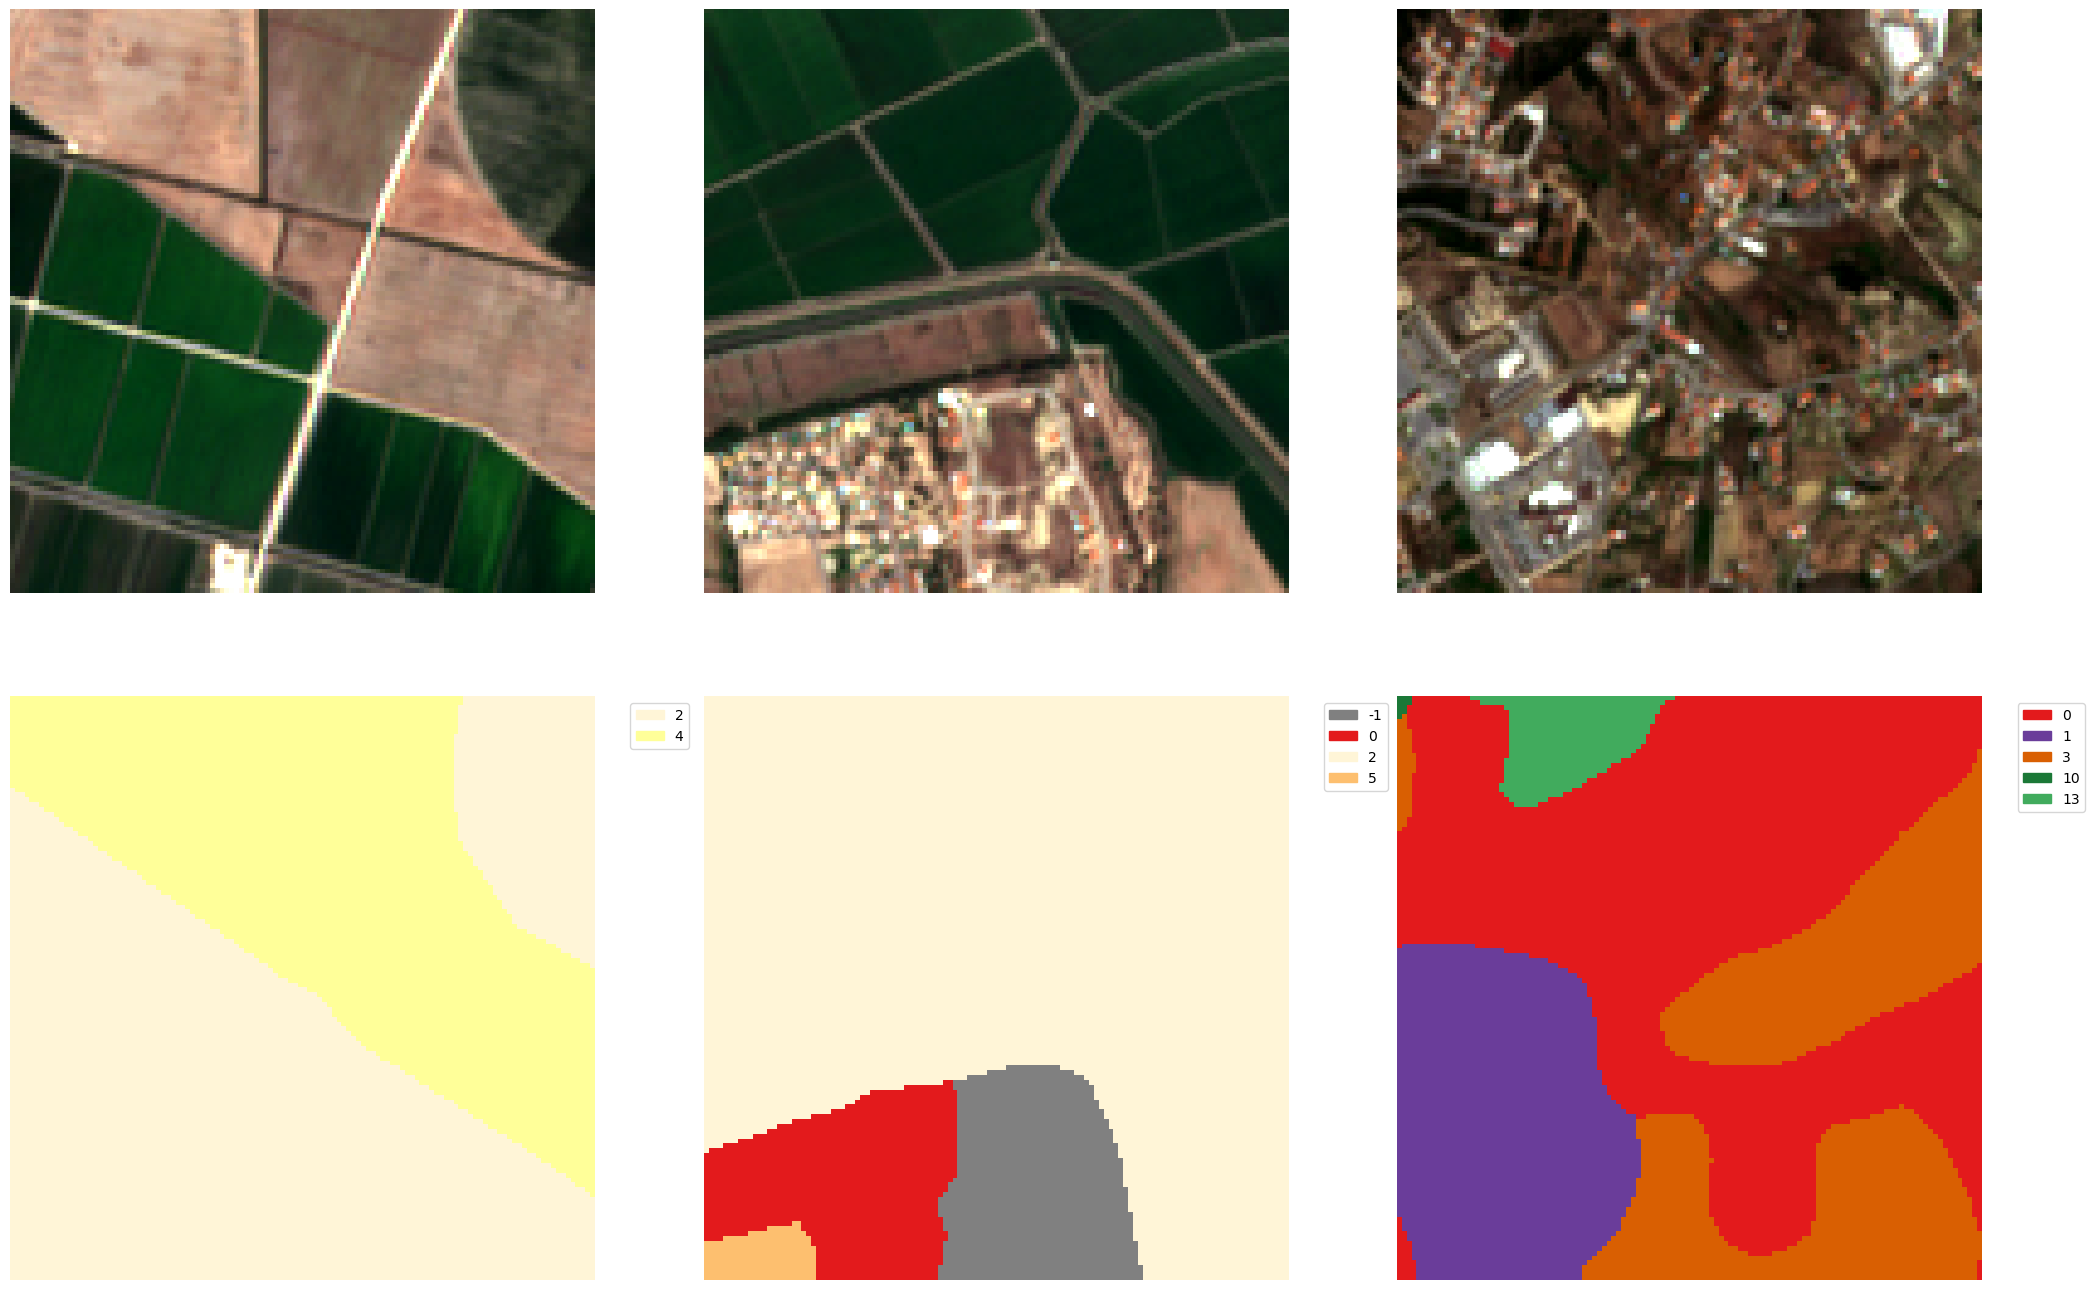

In [ ]:
dataset_name = "reben"

img_size = 120
train_transform = A.Compose([#*train_transform_list,
    #A.RandomResizedCrop(size=(img_size, img_size), scale=(0.5, 1.0), ratio=(1.0, 1.0)), 
    ToTensorV2()
], seed=seed)


dataset_cfg = ReBEN7kDataset_Cfg(
    data_dir=LOCAL_PATHS["reben_dir"],
    keys_path=LOCAL_PATHS["reben_keys"],
    split_file="../datasets/metadata/reben_7k.csv",
    split=split,
    align_size=120,
    bands=["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12"],
    normalize=True,
    transform=train_transform,
    val_to_train_frac=0.0,
    test_to_train_frac=0.0,
    seed=seed,
    blocklist_path=None,
    return_mask=True,
    crop_size=None,
    grid_sampling=False,
    min_margin=None,
)

dataset = ReBEN7kDataset(**asdict(dataset_cfg))

print("finished dataset init")
print("Number of tiles:", len(dataset.tiles))
print(f"Dataset length (Number of crops): {dataset.grid_coords}")
print(f"Margin Y: {dataset.margin_y}, Margin X: {dataset.margin_x}")

# Check offset stability vs epoch
dataset.shift_grid(0)
print("Epoch 0: first tile offset:", dataset.offsets)
imgs, masks = [], []
for i in range(0,3):
    img, mask = dataset[i]
    imgs.append(quant_norm(img[[2, 1, 0], ...])); masks.append(mask)

plot_images([*imgs, *masks], dataset_name=dataset_name,
            ncols=3)

dataset.shift_grid(1)
print("Epoch 1: first tiles offsets:", dataset.offsets)
imgs, masks = [], []
for i in range(0,3):
    img, mask = dataset[i]
    imgs.append(quant_norm(img[[2, 1, 0], ...])); masks.append(mask)

plot_images([*imgs, *masks], dataset_name=dataset_name,
            ncols=3)


# Single big tile dataset: C2Seg - Wuhan


C2Seg Config:
Number of tiles: 1
Dataset length (Number of crops): 90
Margin Y: 161, Margin X: 171
Epoch 0: first tile offset: [[102  92]]


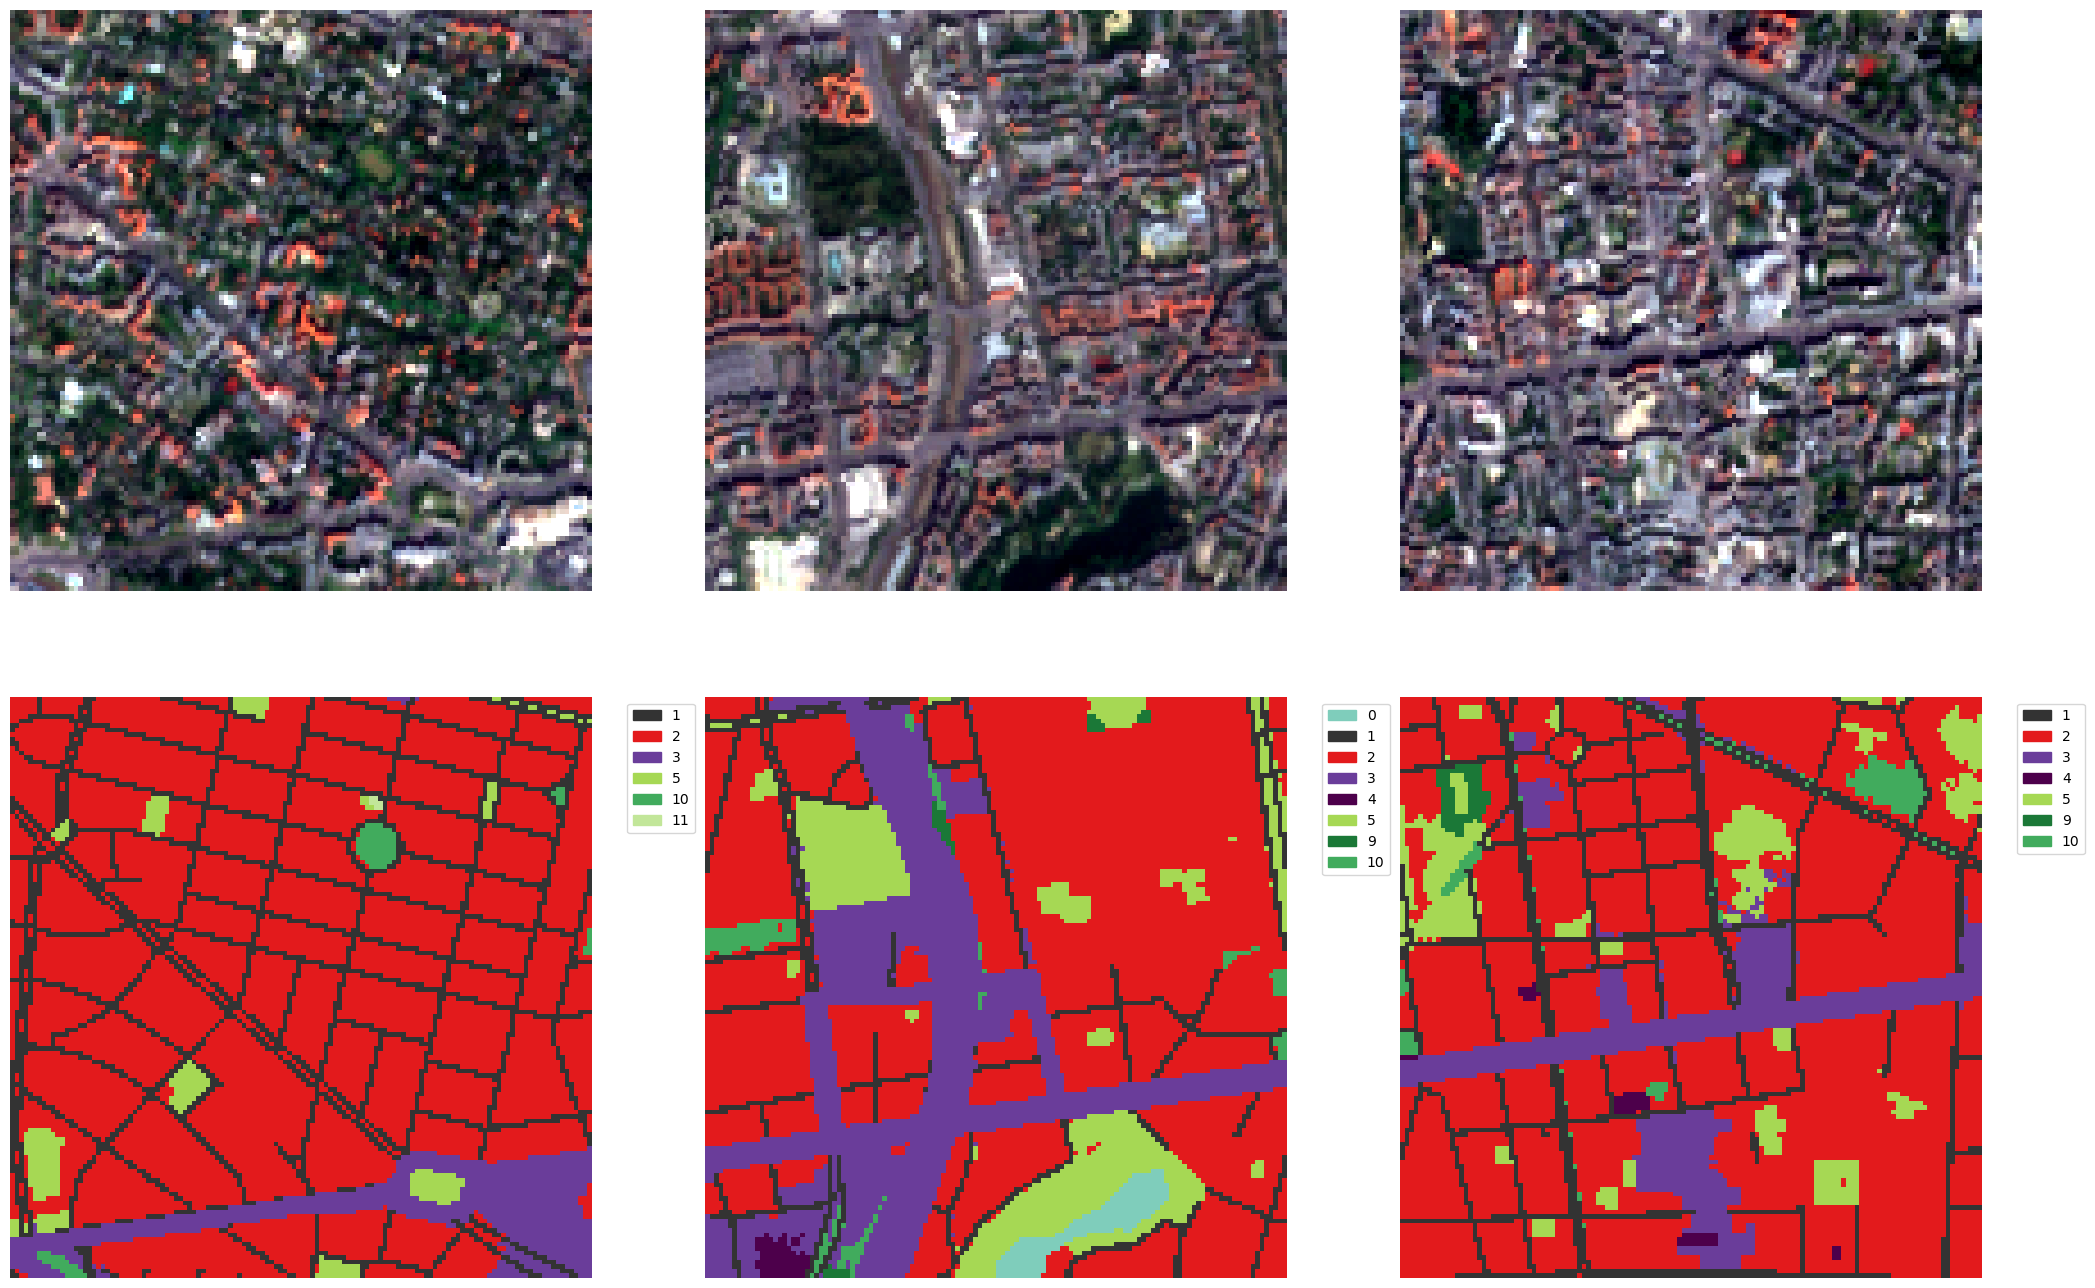

Epoch 1: first tiles offsets: [[ 14 106]]


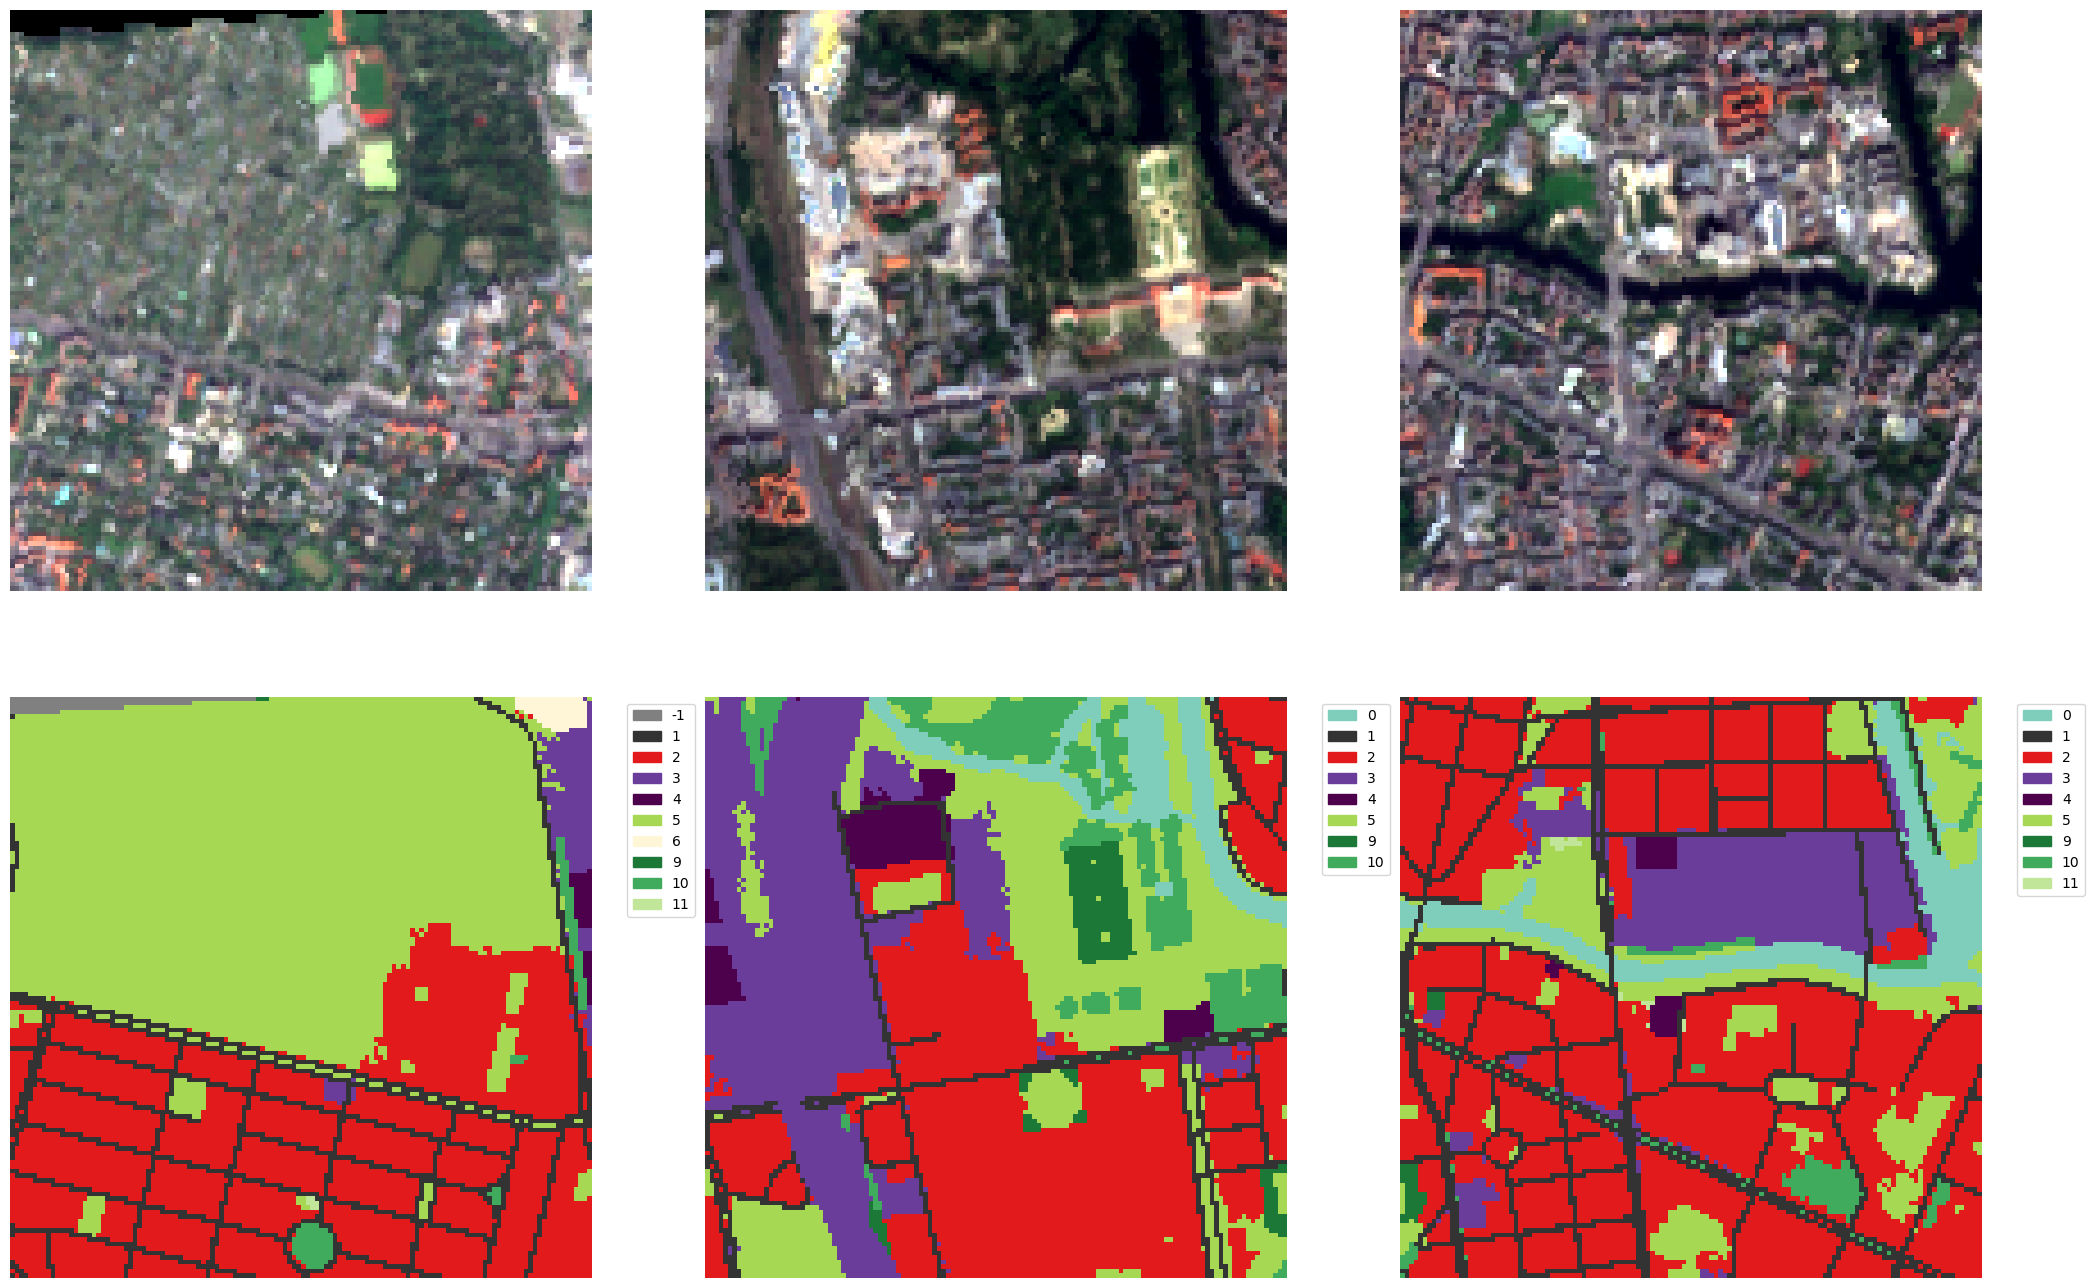

In [8]:
dataset_name = "c2seg"

train_transform = A.Compose([#*train_transform_list,
    #A.RandomResizedCrop(size=(img_size, img_size), scale=(0.5, 1.0), ratio=(1.0, 1.0)), 
    ToTensorV2()
], seed=seed)

dataset_cfg = C2SegDataset_Cfg(
    data_dir=LOCAL_PATHS["c2seg_dir"],
    split="berlin",
    bands=["B02", "B03", "B04", "B08"],
    normalize=True,
    transform=train_transform,
    crop_size=128,
    grid_sampling=True,
    min_margin=64,
    seed=seed,
)

print("\nC2Seg Config:")

dataset = C2SegDataset(**asdict(dataset_cfg))

print("Number of tiles:", len(dataset.tiles))
print(f"Dataset length (Number of crops): {len(dataset.grid_coords)}")
print(f"Margin Y: {dataset.margin_y}, Margin X: {dataset.margin_x}")

# Check offset stability vs epoch
dataset.shift_grid(0)
print("Epoch 0: first tile offset:", dataset.offsets)
imgs, masks = [], []
for i in range(0,3):
    img, mask = dataset[i]
    imgs.append(quant_norm(img[[2, 1, 0], ...])); masks.append(mask)

plot_images([*imgs, *masks], dataset_name=dataset_name,
            ncols=3)

dataset.shift_grid(1)
print("Epoch 1: first tiles offsets:", dataset.offsets)
imgs, masks = [], []
for i in range(0,3):
    img, mask = dataset[i]
    imgs.append(quant_norm(img[[2, 1, 0], ...])); masks.append(mask)

plot_images([*imgs, *masks], dataset_name=dataset_name,
            ncols=3)


In [9]:
img

tensor([[[ 0.1921,  0.0851,  0.5809,  ...,  0.5249,  0.2630,  0.2350],
         [ 0.3437,  0.4261,  0.6699,  ...,  0.2284,  0.0636, -0.0517],
         [ 0.0505,  0.4211,  0.5117,  ..., -0.1028, -0.1341, -0.0731],
         ...,
         [ 0.4590,  0.6089,  0.8214,  ...,  0.5611,  0.6089,  0.5233],
         [ 0.2860,  0.4195,  0.4195,  ...,  1.2349,  1.0191,  0.6863],
         [ 0.2498,  0.4145,  0.5002,  ...,  0.9054,  0.5595,  0.6353]],

        [[ 0.2966,  0.2088,  0.7226,  ...,  0.4060,  0.0844,  0.0745],
         [ 0.5353,  0.5535,  0.6729,  ...,  0.0844, -0.1443, -0.1542],
         [ 0.0016,  0.3778,  0.3878,  ..., -0.1874, -0.2421, -0.1377],
         ...,
         [ 0.5303,  0.7209,  0.9746,  ...,  0.2950,  0.3977,  0.3629],
         [ 0.3397,  0.5336,  0.4010,  ...,  1.1817,  0.8154,  0.6331],
         [ 0.3331,  0.5121,  0.4557,  ...,  0.9762,  0.6198,  0.7243]],

        [[ 1.1607,  1.0278,  1.4952,  ...,  0.5092,  0.1557,  0.1382],
         [ 1.0643,  1.3930,  0.8613,  ...,  0

# Small tiles dataset: Burn Scars

finished dataset init
Number of tiles: 524
Dataset length (Number of crops): 4716
Margin Y: 128, Margin X: 128
Epoch 0: first tile offset: [[102  92]
 [ 14 106]
 [ 71  20]
 ...
 [ 95 122]
 [ 38  45]
 [ 28  61]]


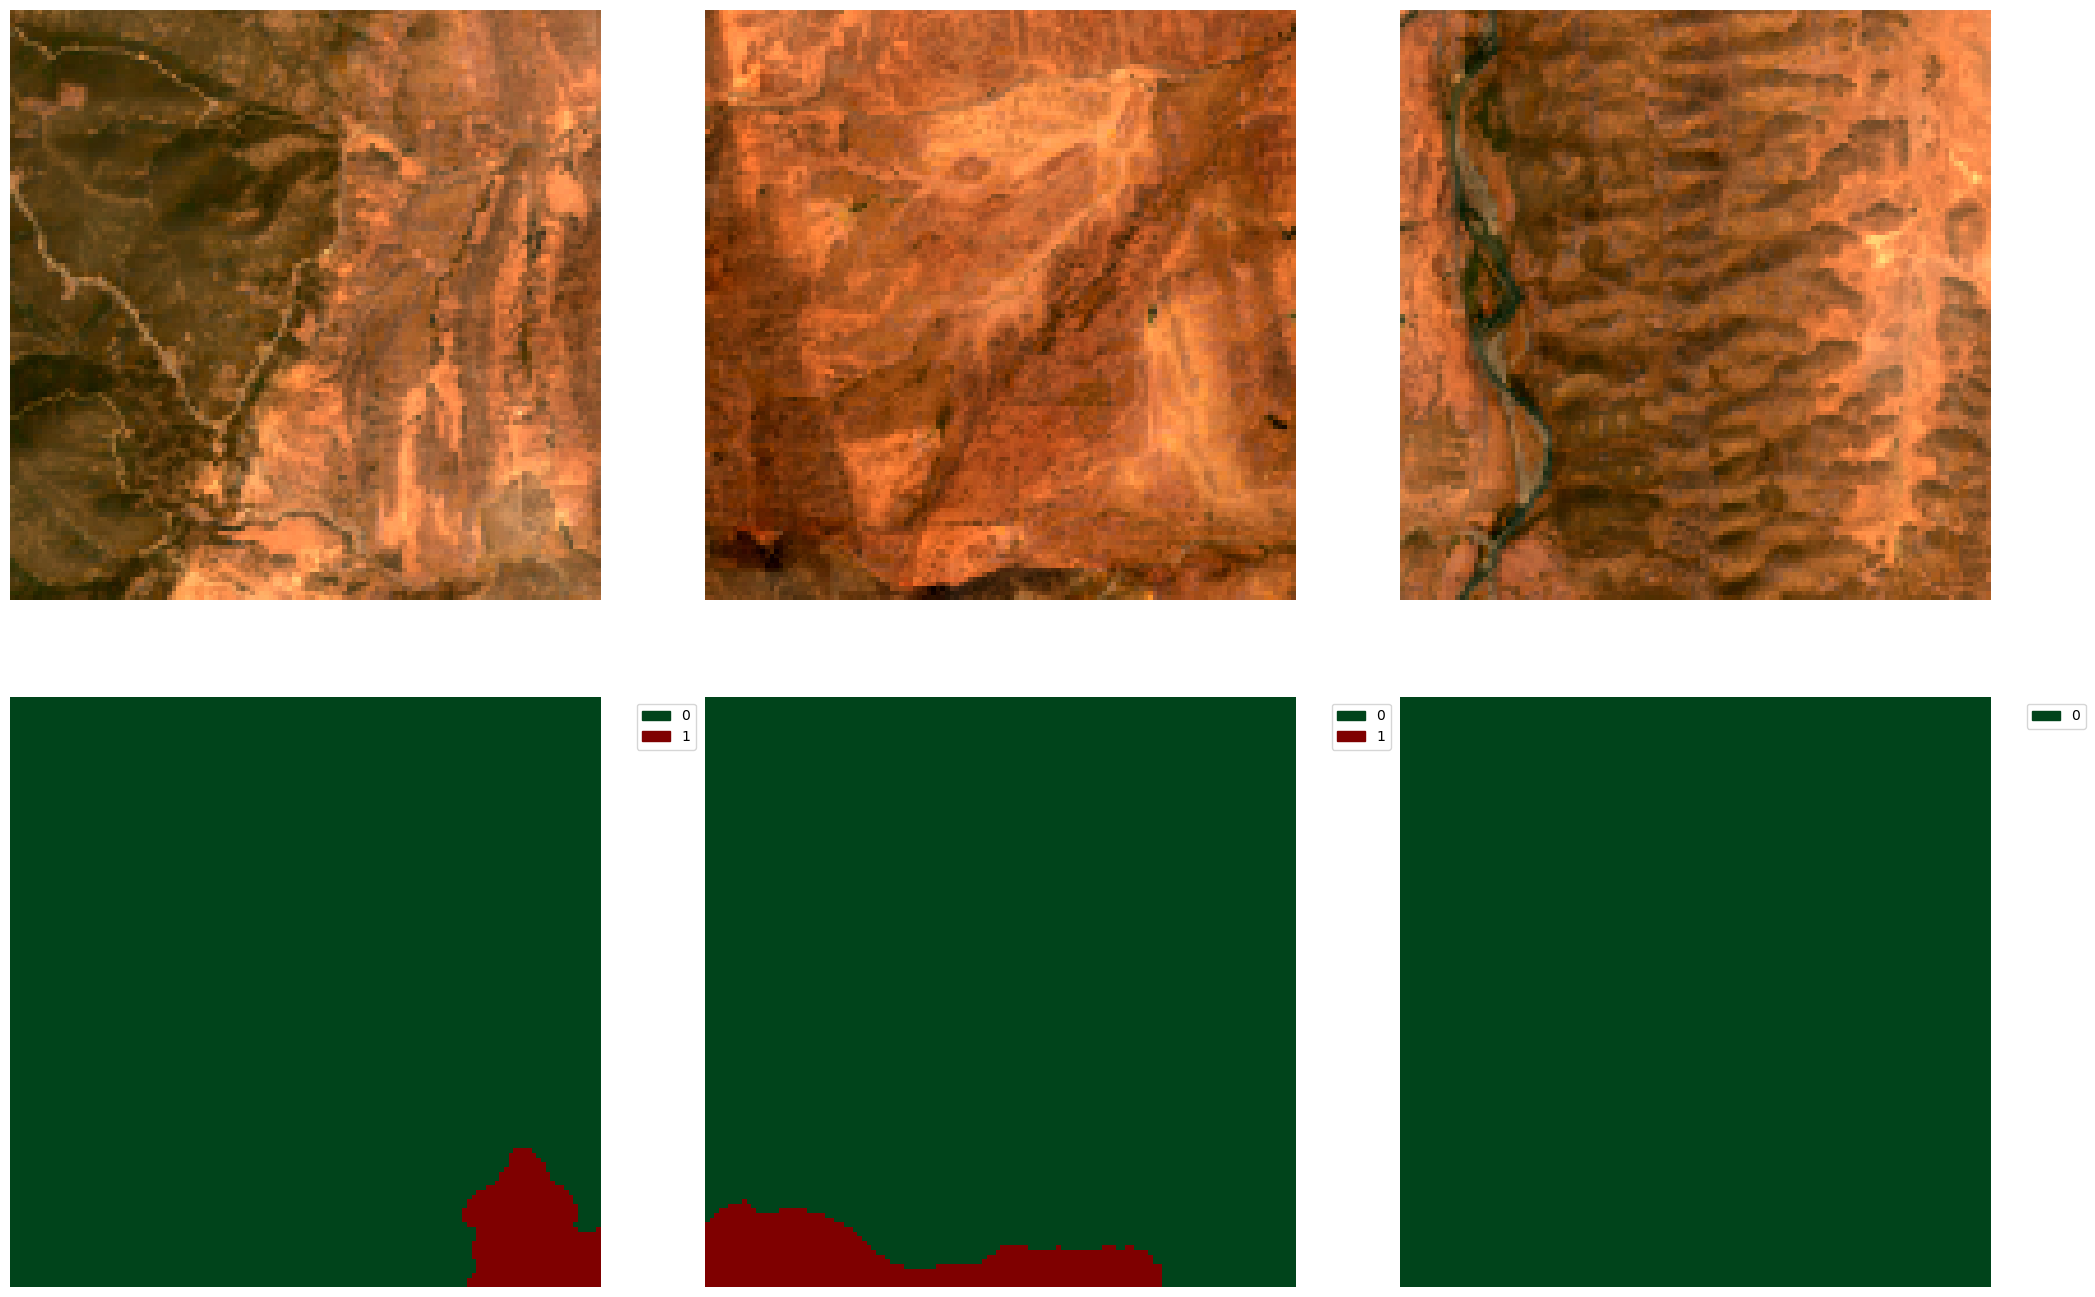

Epoch 1: first tiles offsets: [[ 15 120]
 [  9 102]
 [ 83  64]
 ...
 [ 54  46]
 [103  41]
 [ 59  11]]


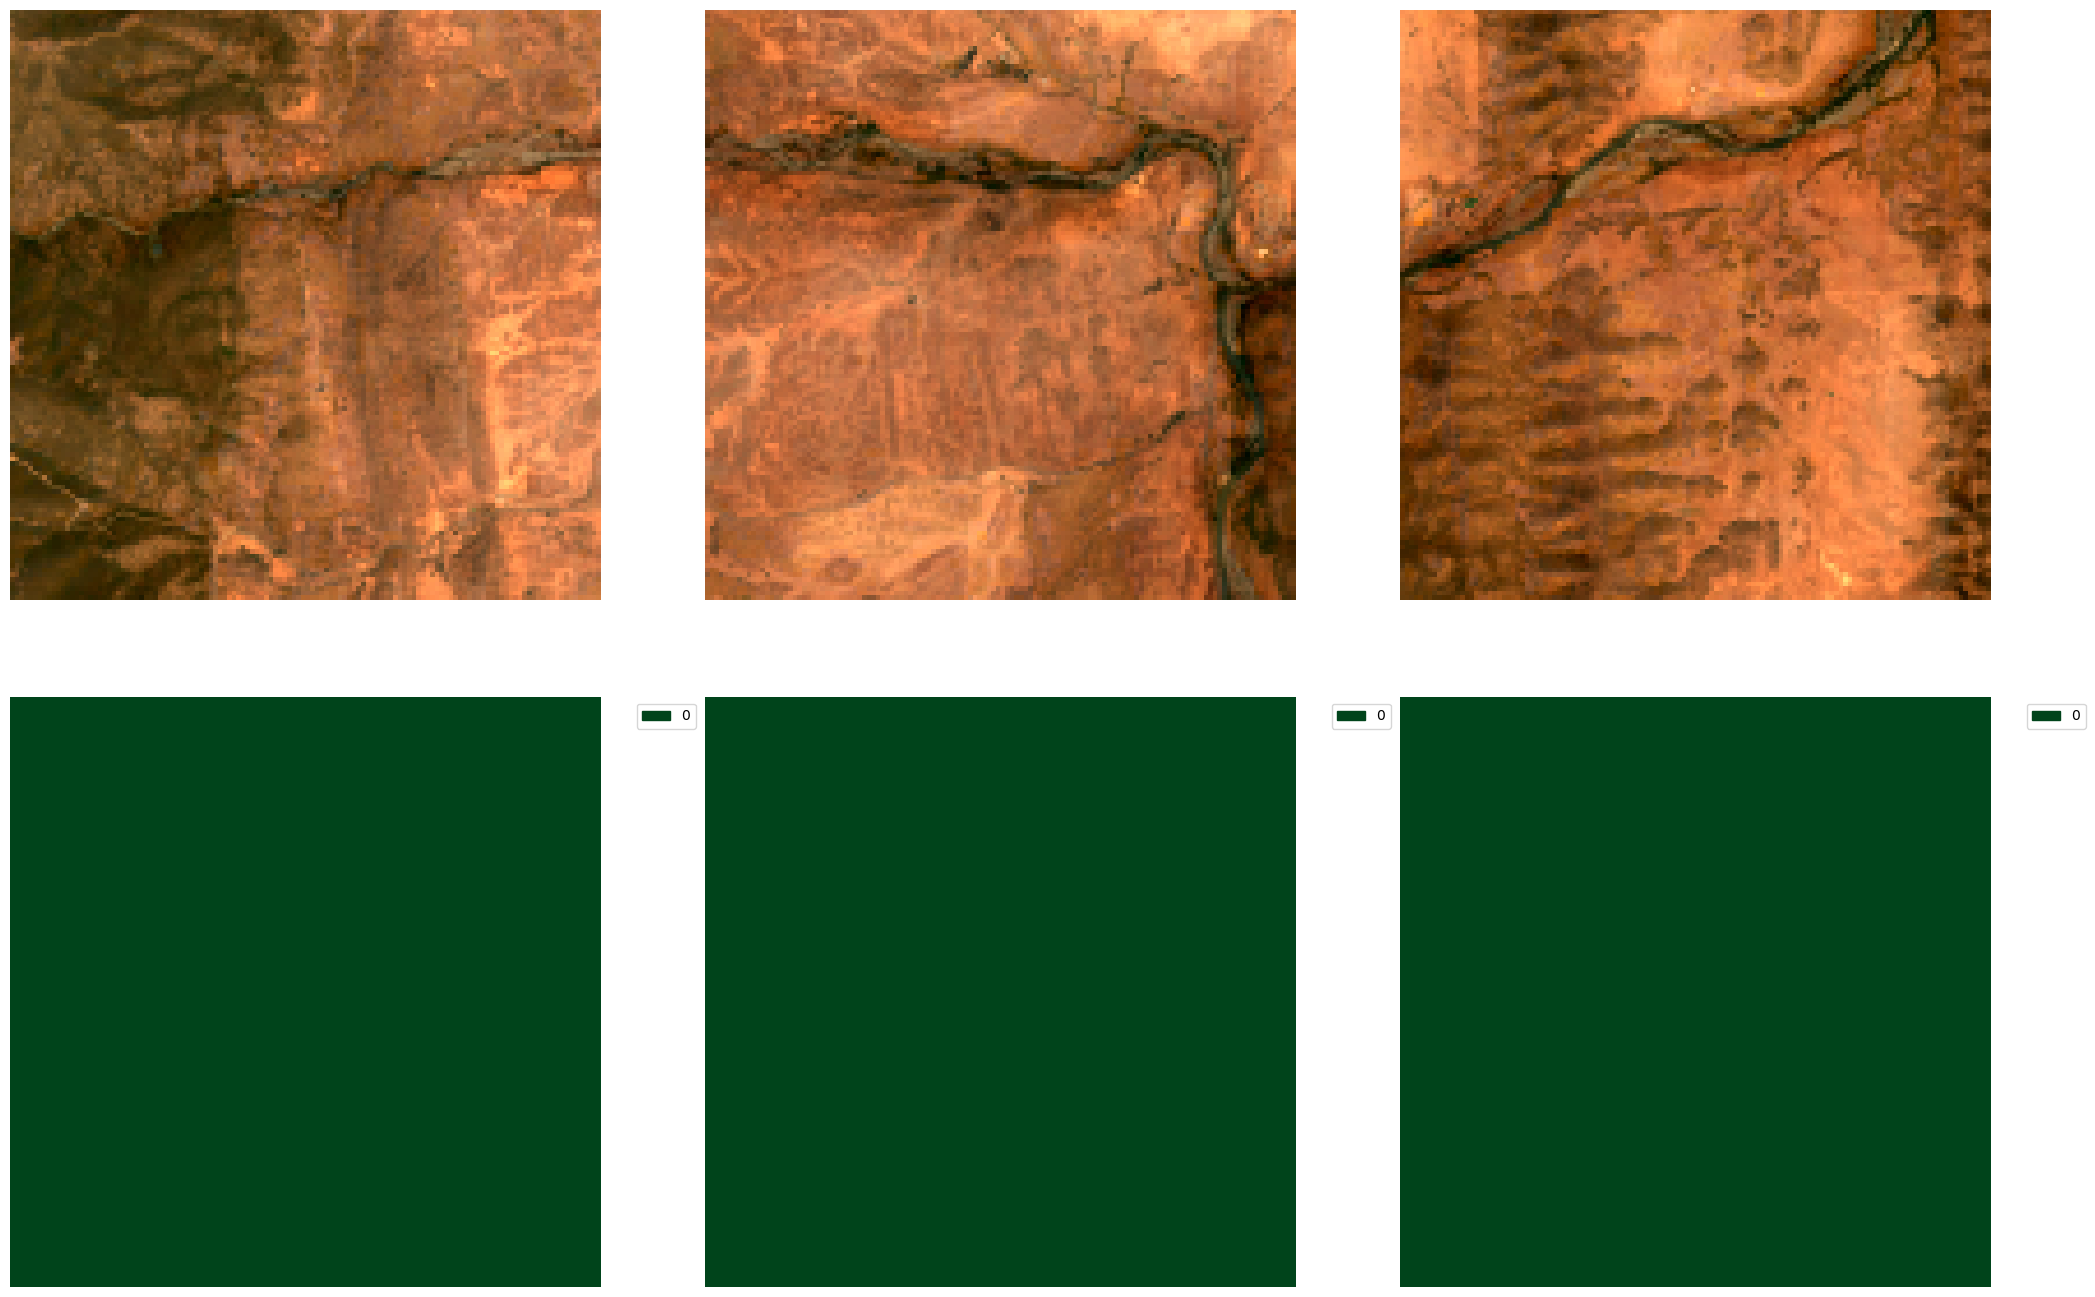

In [ ]:
dataset_name = "burn_scars"

img_size = 128

train_transform = A.Compose([#*train_transform_list,
    A.RandomResizedCrop(size=(img_size, img_size), scale=(0.5, 1.0), ratio=(1.0, 1.0)), 
    ToTensorV2()
], seed=seed)

dataset_cfg = BurnScarsDataset_Cfg(
    data_dir=LOCAL_PATHS["burn_scars_dir"],
    split_file="../datasets/metadata/burn_scars.csv",
    split=split,
    bands=["B02", "B03", "B04", "B8A", "B11", "B12"],
    normalize=False,##################True,
    transform=train_transform,
    crop_size=128,
    grid_sampling=True,
    min_margin=64,
    seed=seed,
)

dataset = BurnScarsDataset(**asdict(dataset_cfg))

print("finished dataset init")
print("Number of tiles:", len(dataset.tiles))
print(f"Dataset length (Number of crops): {len(dataset.grid_coords)}")
print(f"Margin Y: {dataset.margin_y}, Margin X: {dataset.margin_x}")

# Check offset stability vs epoch
dataset.shift_grid(0)
print("Epoch 0: first tile offset:", dataset.offsets)
imgs, masks = [], []
for i in range(0,3):
    img, mask = dataset[i]
    imgs.append(quant_norm(img[[2, 1, 0], ...])); masks.append(mask)

plot_images([*imgs, *masks], dataset_name=dataset_name,
            ncols=3)

dataset.shift_grid(1)
print("Epoch 1: first tiles offsets:", dataset.offsets)
imgs, masks = [], []
for i in range(0,3):
    img, mask = dataset[i]
    imgs.append(quant_norm(img[[2, 1, 0], ...])); masks.append(mask)

plot_images([*imgs, *masks], dataset_name=dataset_name,
            ncols=3)


In [ ]:
sen1floods11_cfg = Sen1Floods11Dataset_Cfg(
    data_dir=LOCAL_PATHS["sen1floods11_dir"],
    split_file="datasets/metadata/sen1floods11.csv",
    split=split,
    bands=["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12"],
    normalize=True,
    transform=train_transform,
    crop_size=128,
    grid_sampling=True,
    min_margin=64,
    seed=seed,
)

print("\nSen1Floods11 Config:")
pprint(asdict(sen1floods11_cfg))

ds_sen1floods11 = Sen1Floods11Dataset(**asdict(sen1floods11_cfg))